<a href="https://colab.research.google.com/github/valverdeelias951-cell/ProyectoP1/blob/main/Proyecto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Parcial I Predicción del rendimiento académico con aprendizaje automático

**Integrantes:**
- EVELYN BRITTANI AGUIRRE ZAMBRANO
- ERICK FERNANDO FUERTES ALCIVAR
- HELEN ANAHI MISES MEZA
-  ELIAS ESTEBAN VALVERDE BENALCAZAR

**Paralelo:** CDDEIA-ELMA-4-1

**Fecha:** 29/11/2026

## Librerias

In [98]:
# Librerías principales
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, confusion_matrix)

sns.set_style("whitegrid")

# Semilla del grupo (NO puede ser 42). Justificarla en la celda de texto de abajo.
SEMILLA = 2026

In [99]:

URL = "https://raw.githubusercontent.com/valverdeelias951-cell/ProyectoP1/main/student-mat.csv"

df = None
for ruta in ["student-mat.csv", "/student-mat.csv"]:
    if os.path.exists(ruta):
        df = pd.read_csv(ruta)
        break
if df is None:
    df = pd.read_csv(URL)

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**Justificación de la semilla:** Elegimos la semilla 2026, que corresponde al año en que desarrollamos este proyecto. Usamos una semilla fija para que los resultados sean reproducibles: con el mismo número, la división entre entrenamiento (80 %) y prueba (20 %) y la elección al azar de los valores faltantes son siempre las mismas, y cualquier integrante del grupo o el docente puede obtener exactamente las mismas métricas al ejecutar el notebook. No elegimos el 42, como indica la consigna, y este valor tampoco fue seleccionado por ofrecer mejores resultados: no probamos varias semillas para quedarnos con la que diera mejores métricas, ya que eso sería sesgar la evaluación del modelo.

# Parte 1. Análisis exploratorio de datos (EDA)

## 1.1 Estructura del dataset

In [100]:
# Dimensiones del dataset
print("Filas y columnas:", df.shape)

# Tipos de variables y valores no nulos
df.info()

Filas y columnas: (395, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-nu

In [101]:
# Estadísticas descriptivas de las variables numéricas
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**Descripción de la estructura:** El dataset tiene 395 filas (estudiantes) y 33 columnas, sin valores nulos. Hay 16 variables numéricas (como age, studytime, absences, G1, G2 y G3) y 17 categóricas (como school, sex, Mjob e internet). En las estadísticas descriptivas, las notas G1, G2 y G3 promedian alrededor de 10 a 11 puntos sobre 20. En absences el promedio es bajo, pero el máximo es muy alto, lo que sugiere valores atípicos.



In [102]:
# Estadísticas de las variables categóricas
df.describe(include="object")

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,307,281,354,141,217,145,273,344,242,214,201,314,375,329,263


## 1.2 Distribución de G3 y de variables relevantes

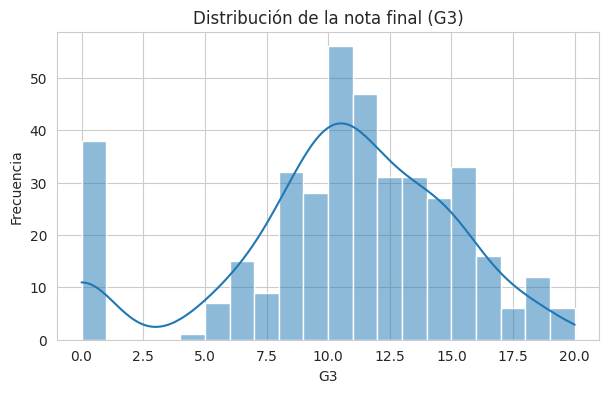

Estudiantes con G3 = 0: 38


In [103]:
# Distribución de la nota final G3
plt.figure(figsize=(7, 4))
sns.histplot(df["G3"], bins=20, kde=True)
plt.title("Distribución de la nota final (G3)")
plt.xlabel("G3")
plt.ylabel("Frecuencia")
plt.show()

print("Estudiantes con G3 = 0:", (df["G3"] == 0).sum())

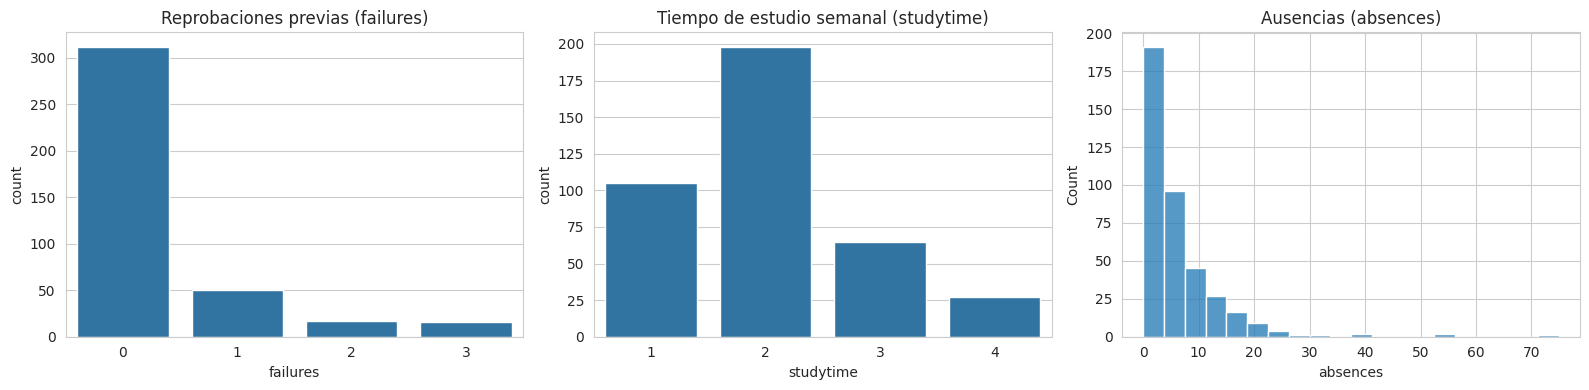

In [104]:
# Tres variables relevantes: failures, studytime y absences
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="failures", data=df, ax=axes[0])
axes[0].set_title("Reprobaciones previas (failures)")

sns.countplot(x="studytime", data=df, ax=axes[1])
axes[1].set_title("Tiempo de estudio semanal (studytime)")

sns.histplot(df["absences"], bins=20, ax=axes[2])
axes[2].set_title("Ausencias (absences)")

plt.tight_layout()
plt.show()

**Interpretación de las distribuciones:** G3 tiene forma de campana entre 8 y 16 puntos, con el máximo cerca de 10 y 11. Además hay un grupo aparte de unos 38 estudiantes con nota 0, lo que da dos picos y sugiere casos de abandono o de no rendir el examen final. En failures casi todos tienen 0 reprobaciones previas, en studytime la mayoría estudia entre 2 y 5 horas semanales, y absences está sesgada a la derecha: pocas ausencias en general y unos pocos valores muy altos.


## 1.3 Matriz de correlación

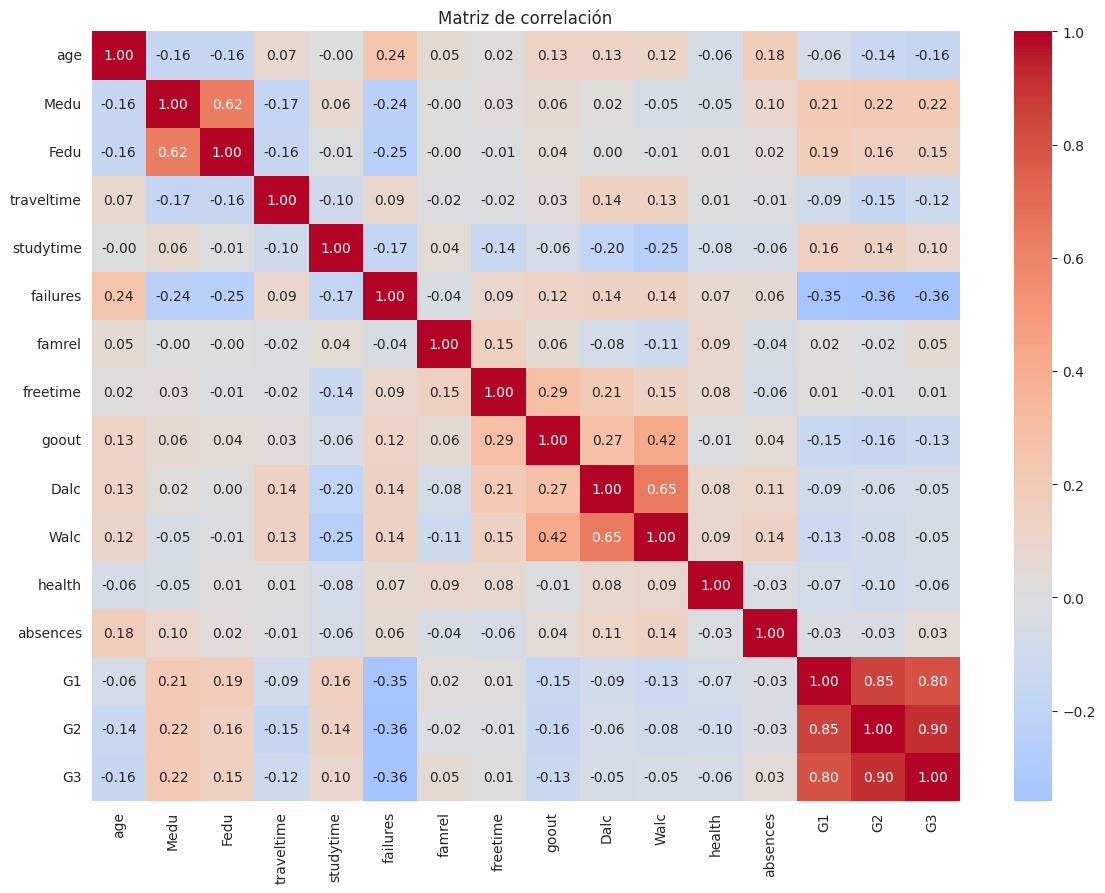

,G3
G2,0.904868
G1,0.801468
failures,-0.360415
Medu,0.217147
age,-0.161579
Fedu,0.152457
goout,-0.132791
traveltime,-0.117142
studytime,0.097820
health,-0.061335


In [105]:
# Solo variables numéricas
num = df.select_dtypes(include="number")
corr = num.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

# Variables más relacionadas con G3 (ordenadas por valor absoluto)
corr_g3 = corr["G3"].drop("G3")
corr_g3.reindex(corr_g3.abs().sort_values(ascending=False).index)

**Variables más relacionadas con G3:** Las más relacionadas con G3 son G2 y G1, con una relación positiva muy fuerte (G2 cerca de 0.90 y G1 cerca de 0.80). Le sigue failures, con una relación negativa (cerca de -0.36): a más reprobaciones previas, menor nota final. Medu (0.22) y Fedu (0.15) tienen una relación positiva débil, mientras que age (-0.16) y goout (-0.13) tienen una relación negativa débil. studytime (0.10) y absences (0.03) casi no muestran relación lineal con G3.

Es importante notar que G1 y G2 son notas de períodos anteriores, por lo que su alta correlación con G3 es esperable y no necesariamente útil para anticipar el riesgo a tiempo. Además, la correlación mide solo relaciones lineales entre pares de variables y no implica causalidad.

## 1.4 Tres hallazgos



In [106]:
# Datos de apoyo para redactar los hallazgos
print("Nota promedio según reprobaciones previas:")
print(df.groupby("failures")["G3"].mean().round(2), "\n")

print("Nota promedio según tiempo de estudio:")
print(df.groupby("studytime")["G3"].mean().round(2), "\n")

print("Nota promedio según deseo de estudios superiores:")
print(df.groupby("higher")["G3"].mean().round(2))

Nota promedio según reprobaciones previas:
failures
0    11.25
1     8.12
2     6.24
3     5.69
Name: G3, dtype: float64 

Nota promedio según tiempo de estudio:
studytime
1    10.05
2    10.17
3    11.40
4    11.26
Name: G3, dtype: float64 

Nota promedio según deseo de estudios superiores:
higher
no      6.80
yes    10.61
Name: G3, dtype: float64


**Hallazgos:**

1. Los estudiantes con reprobaciones previas tienen en promedio notas finales más bajas: quienes no han reprobado ninguna asignatura promedian 11.25 puntos en G3, mientras que quienes han reprobado una o más promedian bastante menos (entre 8.12 con una reprobación y 5.69 con tres).
2. Las notas de los períodos anteriores predicen muy bien la nota final: G1 y G2 tienen una correlación positiva fuerte con G3 (alrededor de 0.80 y 0.90), así que quien rinde bien al inicio suele terminar bien.
3. Hay un grupo de unos 38 estudiantes con nota final 0, separado del resto de la distribución. Esto sugiere abandono o no presentación del examen final, y puede afectar los modelos.

# Parte 2. Preprocesamiento

## 2.1 Faltantes y duplicados

In [107]:
# Revisión del dataset original
print("Faltantes en el dataset original:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

Faltantes en el dataset original: 0
Filas duplicadas: 0


In [108]:
# El dataset original no tiene faltantes: se introduce un 5 % al azar
# en absences y en studytime, usando la semilla del grupo.
df_nan = df.copy()
rng = np.random.default_rng(SEMILLA)
n_faltantes = int(round(0.05 * len(df_nan)))

for col in ["absences", "studytime"]:
    idx = rng.choice(df_nan.index, size=n_faltantes, replace=False)
    df_nan[col] = df_nan[col].astype(float)
    df_nan.loc[idx, col] = np.nan

print("Faltantes introducidos:")
print(df_nan[["absences", "studytime"]].isnull().sum())

Faltantes introducidos:
absences     20
studytime    20
dtype: int64


**Estrategia de imputación elegida:** se usa la **mediana** (dentro del Pipeline, ver 2.4).

Elegimos la mediana y no la media porque absences tiene una distribución muy sesgada a la derecha, con algunos valores extremos (hasta 75 ausencias), y la media se deja arrastrar por esos casos y daría un valor poco representativo. La mediana, en cambio, no se ve afectada por los extremos. En studytime, que es una escala ordinal de 1 a 4, la mediana además es un valor que existe en la escala, mientras que la media podría dar un número intermedio sin sentido.

Imputamos dentro del Pipeline para evitar la fuga de datos: así la mediana se calcula solo con los datos de entrenamiento y luego se aplica a los de prueba. Si la calculáramos con todo el dataset, el conjunto de prueba influiría en el preprocesamiento y las métricas saldrían más optimistas de lo real.

## 2.2 Valores atípicos en absences (regla IQR)

Q1 = 0.0, Q3 = 8.0, IQR = 8.0
Límites: [-12.00, 20.00]
Cantidad de atípicos: 15
Máximo de ausencias: 75


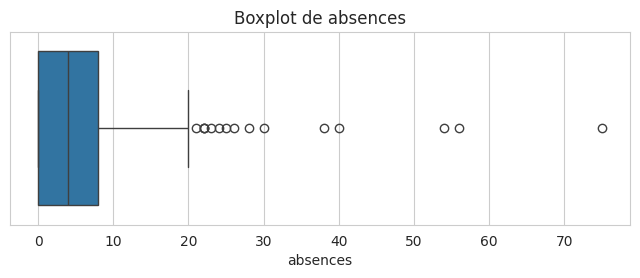

In [109]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

atipicos = df[(df["absences"] < lim_inf) | (df["absences"] > lim_sup)]
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Límites: [{lim_inf:.2f}, {lim_sup:.2f}]")
print("Cantidad de atípicos:", len(atipicos))
print("Máximo de ausencias:", df["absences"].max())

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df["absences"])
plt.title("Boxplot de absences")
plt.show()

**Decisión sobre los atípicos:** Decidimos conservarlos. Con la regla IQR, las ausencias por encima del límite superior (más de 20 ausencias, 15 estudiantes) no parecen errores de medición, sino ausencias reales: un estudiante puede faltar muchas veces, y eso es justo la información que nos interesa para detectar riesgo. Eliminarlos nos haría perder casos de estudiantes en situación difícil, y con solo 395 filas cada observación cuenta.

Sabemos que estos valores pueden influir en la regresión lineal, porque los coeficientes son sensibles a los extremos y pueden alejarse del comportamiento del resto. Por eso lo tenemos presente al revisar los supuestos y los residuos del Modelo B.

Sobre el preprocesamiento: la imputación con mediana no se ve afectada por los atípicos, pero el StandardScaler sí, porque calcula la media y la desviación estándar, y un valor como 75 las aumenta. Como consecuencia, la mayoría de los estudiantes queda con valores escalados de absences muy parecidos entre sí, y los atípicos quedan muy lejos del resto. Aceptamos esa limitación para no perder información, aunque una alternativa sería aplicar una transformación logarítmica a absences o usar un escalador robusto.

## 2.3 Codificación y escalado
- **One-Hot Encoding** para las variables categóricas (`school`, `sex`, `Mjob`, etc.), porque los modelos no entienden texto y no existe un orden entre sus categorías.
- **StandardScaler** para las numéricas.

**Justificación del escalado:** Escalamos las variables numéricas con StandardScaler porque tienen unidades y rangos muy distintos: age va de 15 a 22, absences de 0 a 75 y studytime de 1 a 4. Sin escalar, las variables con números más grandes pesarían más de lo que les corresponde en los modelos que penalizan los coeficientes.

Esto importa en la regresión logística, que por defecto en scikit-learn usa regularización, y en Ridge y Lasso de la bonificación: la penalización castiga igual a todos los coeficientes, y si las variables no están en la misma escala, la penalización afecta de forma injusta a unas más que a otras. También ayuda a que el algoritmo de la regresión logística converja mejor.

Además, escalar permite comparar los coeficientes entre variables, porque quedan en unidades comparables (desviaciones estándar) y se ve cuáles influyen más. En la regresión lineal simple el escalado no cambia las predicciones, pero sí facilita esa interpretación.

## 2.4 Pipeline con ColumnTransformer y división train/test

In [110]:
def crear_preprocesador(X):
    # Preprocesador: imputa y escala numéricas; codifica categóricas
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = X.select_dtypes(include="object").columns.tolist()

    num_pipe = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ])

    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

# Variables y objetivo (con los faltantes introducidos)
X = df_nan.drop(columns="G3")
y = df_nan["G3"]

# División 80 % entrenamiento / 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (316, 32) | Test: (79, 32)


# Parte 3. Regresión lineal múltiple: predecir G3

- **Modelo A:** todas las variables, incluidas G1 y G2.
- **Modelo B:** todas las variables excepto G1 y G2.

## 3.1 Entrenamiento y métricas

In [111]:
# Datos de cada modelo (mismas filas de train/test para ambos)
X_train_A, X_test_A = X_train, X_test
X_train_B = X_train.drop(columns=["G1", "G2"])
X_test_B = X_test.drop(columns=["G1", "G2"])

def entrenar_lineal(X_tr, X_te):
    modelo = Pipeline([
        ("prep", crear_preprocesador(X_tr)),
        ("modelo", LinearRegression())
    ])
    modelo.fit(X_tr, y_train)
    return modelo, modelo.predict(X_te)

modelo_A, pred_A = entrenar_lineal(X_train_A, X_test_A)
modelo_B, pred_B = entrenar_lineal(X_train_B, X_test_B)

def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_real, y_pred)}

resultados = pd.DataFrame({
    "Modelo A (con G1 y G2)": metricas(y_test, pred_A),
    "Modelo B (sin G1 ni G2)": metricas(y_test, pred_B)
}).T.round(3)
resultados

,MSE,RMSE,R2
Modelo A (con G1 y G2),3.297,1.816,0.825
Modelo B (sin G1 ni G2),18.172,4.263,0.036


**Interpretación de los resultados:** El MSE es el promedio de los errores al cuadrado, y el RMSE es su raíz, así que se lee en puntos de nota: indica cuánto se equivoca el modelo en promedio al predecir G3. El R² indica qué proporción de la variación de G3 explica el modelo (1 es perfecto y 0 es no explicar nada).

El Modelo A (con G1 y G2) obtuvo un RMSE de 1.816 puntos y un R² de 0.825, es decir, predice la nota final con muy poco error y explica gran parte de su variación. El Modelo B (sin G1 ni G2) obtuvo un RMSE de 4.263 puntos y un R² de 0.036, con un error bastante mayor y un poder explicativo mucho menor. La diferencia es grande porque G2 es casi una versión anticipada de G3, así que le da mucha ventaja al Modelo A. En el Modelo B también influyen los estudiantes con nota 0, que son difíciles de predecir con las demás variables.

## 3.2 Residuos y coeficientes del Modelo B

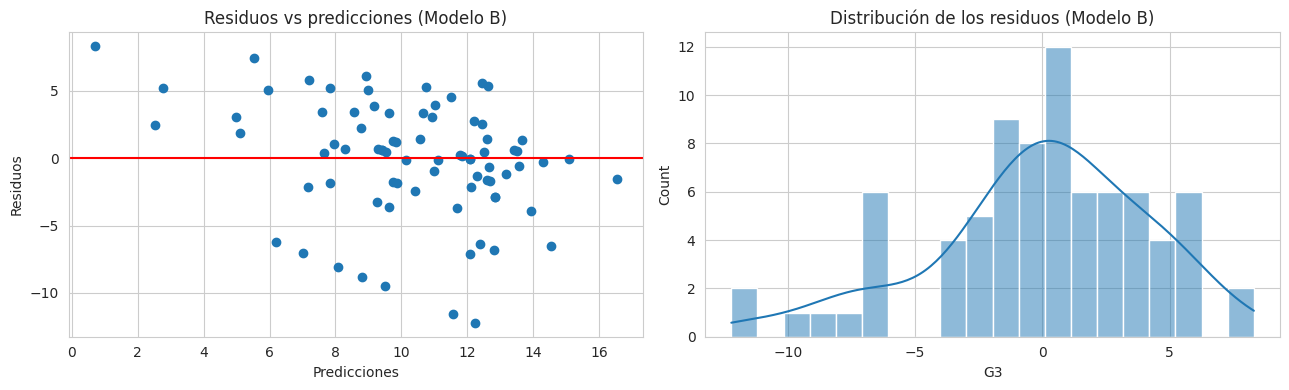

Media de residuos: -0.148
Residuo promedio en estudiantes con G3 = 0: -9.055


,0
cat__Mjob_teacher,-1.731
cat__higher_yes,1.620
cat__schoolsup_yes,-1.503
cat__sex_M,1.491
cat__romantic_yes,-1.339
num__failures,-1.314
cat__Fjob_teacher,1.221
cat__famsize_LE3,1.132


In [112]:
# Residuos del Modelo B
residuos_B = y_test - pred_B

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(pred_B, residuos_B)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicciones")
axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos vs predicciones (Modelo B)")
sns.histplot(residuos_B, bins=20, kde=True, ax=axes[1])
axes[1].set_title("Distribución de los residuos (Modelo B)")
plt.tight_layout()
plt.show()

print("Media de residuos:", round(residuos_B.mean(), 3))
print("Residuo promedio en estudiantes con G3 = 0:", round(residuos_B[y_test == 0].mean(), 3))

# Coeficientes del Modelo B (variables escaladas / codificadas)
nombres = modelo_B.named_steps["prep"].get_feature_names_out()
coef_B = pd.Series(modelo_B.named_steps["modelo"].coef_, index=nombres)
coef_B.reindex(coef_B.abs().sort_values(ascending=False).index).head(8).round(3)

**Interpretación de residuos y coeficientes (Modelo B):** Los residuos tienen media cercana a 0 (-0.15), pero con mucha dispersión (desviación de unos 4.3 puntos). En la gráfica de residuos contra predicciones se ven errores grandes y negativos, que corresponden sobre todo a estudiantes con G3 = 0: en el conjunto de prueba hay 7 y el modelo les predice en promedio unos 9 puntos más de lo real. Esto confirma que el abandono o la no presentación del examen es difícil de anticipar sin G1 ni G2 y explica en buena parte el R² bajo.

Entre los coeficientes, los de mayor magnitud son Mjob_teacher (-1.73), higher_yes (+1.62), schoolsup_yes (-1.50), sex_M (+1.49), romantic_yes (-1.34) y failures (-1.31). Quienes quieren estudios superiores o no tienen reprobaciones previas tienden a tener mejores notas. Estos coeficientes describen asociaciones, no causas: por ejemplo, schoolsup_yes es negativo probablemente porque recibe apoyo extra quien ya va peor. Además, los valores atípicos de absences pueden influir en los coeficientes de la regresión lineal.

## 3.3 Cálculo a mano de las métricas del Modelo B

In [113]:
# Métricas del Modelo B calculadas "a mano" con NumPy
y_real = y_test.to_numpy()
errores = y_real - pred_B

mse_np = np.mean(errores ** 2)                        # promedio de errores al cuadrado
rmse_np = np.sqrt(mse_np)                             # raíz del MSE
ss_res = np.sum(errores ** 2)                         # suma de cuadrados de los residuos
ss_tot = np.sum((y_real - y_real.mean()) ** 2)        # variación total de G3
r2_np = 1 - ss_res / ss_tot

comparacion_manual = pd.DataFrame({
    "NumPy (a mano)": [mse_np, rmse_np, r2_np],
    "scikit-learn": [mean_squared_error(y_test, pred_B),
                     np.sqrt(mean_squared_error(y_test, pred_B)),
                     r2_score(y_test, pred_B)]
}, index=["MSE", "RMSE", "R2"]).round(4)
display(comparacion_manual)
print("¿Coinciden los valores?", np.allclose(comparacion_manual["NumPy (a mano)"], comparacion_manual["scikit-learn"]))

,NumPy (a mano),scikit-learn
MSE,18.1722,18.1722
RMSE,4.2629,4.2629
R2,0.0357,0.0357


¿Coinciden los valores? True


El MSE se calculó como el promedio de los errores al cuadrado, el RMSE como su raíz y el R² como 1 menos la suma de cuadrados de los residuos dividida entre la variación total de G3. Los valores de NumPy coinciden con los de scikit-learn, lo que confirma que entendemos qué mide cada métrica y que la librería las calcula como esperábamos.

## 3.4 Revisión de los 5 supuestos de la regresión lineal (Modelo B)

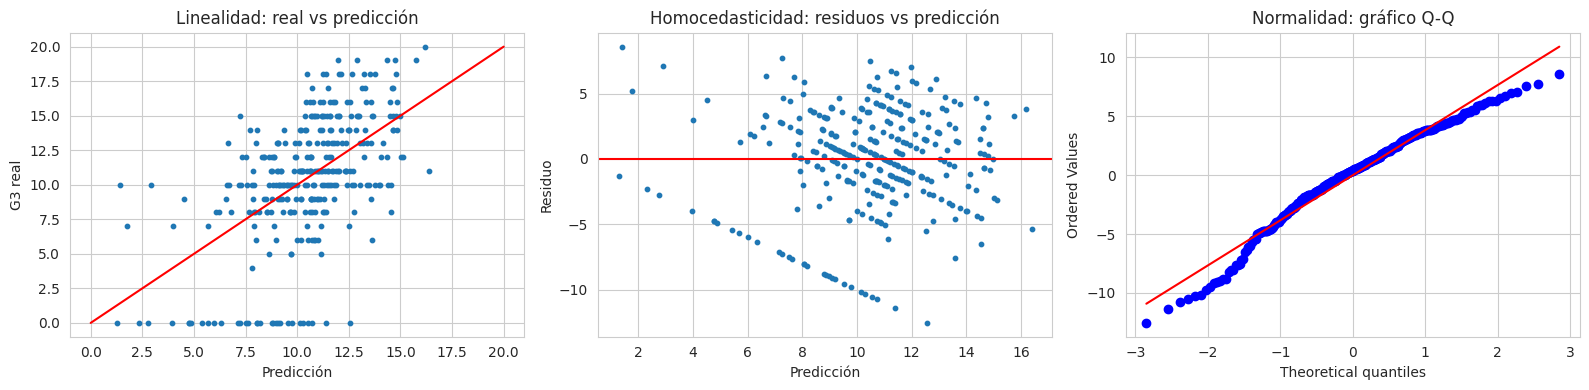

Durbin-Watson: 2.015
Breusch-Pagan, p-valor: 0.223
Shapiro-Wilk, p-valor: 3.865191693476134e-06 | asimetría: -0.668
VIF máximo: 2.16


,0
num__Walc,2.16
num__Dalc,1.79
num__Medu,1.75
num__Fedu,1.72
num__goout,1.33


In [114]:
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Datos de entrenamiento del Modelo B ya transformados por su preprocesador
prep_B = modelo_B.named_steps["prep"]
X_tr_t = pd.DataFrame(prep_B.transform(X_train_B),
                      columns=prep_B.get_feature_names_out(), index=X_train_B.index)
pred_tr = modelo_B.predict(X_train_B)
res_tr = y_train - pred_tr

# Gráficos: linealidad, homocedasticidad y normalidad
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(pred_tr, y_train, s=10)
axes[0].plot([0, 20], [0, 20], color="red")
axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("G3 real")
axes[0].set_title("Linealidad: real vs predicción")
axes[1].scatter(pred_tr, res_tr, s=10)
axes[1].axhline(0, color="red")
axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Residuo")
axes[1].set_title("Homocedasticidad: residuos vs predicción")
stats.probplot(res_tr, dist="norm", plot=axes[2])
axes[2].set_title("Normalidad: gráfico Q-Q")
plt.tight_layout()
plt.show()

# 2. Independencia: Durbin-Watson (cerca de 2 = sin autocorrelación)
print("Durbin-Watson:", round(durbin_watson(res_tr), 3))

# 3. Homocedasticidad: Breusch-Pagan (p > 0.05 = no se rechaza varianza constante)
bp = het_breuschpagan(res_tr, sm.add_constant(X_tr_t))
print("Breusch-Pagan, p-valor:", round(bp[1], 3))

# 4. Normalidad de residuos: Shapiro-Wilk (p > 0.05 = no se rechaza normalidad)
sw = stats.shapiro(res_tr)
print("Shapiro-Wilk, p-valor:", sw.pvalue, "| asimetría:", round(stats.skew(res_tr), 3))

# 5. No multicolinealidad: VIF de las variables numéricas (VIF > 5 o 10 = problema)
num_t = X_tr_t[[c for c in X_tr_t.columns if c.startswith("num__")]]
num_c = sm.add_constant(num_t)
vif = pd.Series([variance_inflation_factor(num_c.values, i) for i in range(1, num_c.shape[1])],
                index=num_t.columns)
print("VIF máximo:", round(vif.max(), 2))
vif.sort_values(ascending=False).round(2).head(5)

**Revisión de los 5 supuestos del Modelo B:**

| Supuesto | Evidencia | Conclusión |
|---|---|---|
| Linealidad | El gráfico de G3 real contra la predicción muestra una tendencia ascendente pero muy dispersa, y los residuos de la masa principal de datos no dibujan una curva. | Se cumple de forma aceptable, aunque la relación es débil (R² bajo). |
| Independencia | Durbin-Watson de 2.015, muy cerca de 2. Cada fila es un estudiante distinto y no hay orden temporal. | Se cumple. No podemos descartar que estudiantes del mismo curso o escuela se parezcan. |
| Homocedasticidad | Breusch-Pagan con p = 0.223 (mayor que 0.05); en el gráfico la dispersión es parecida a lo largo de las predicciones. | Se cumple: no se rechaza varianza constante. |
| Normalidad de residuos | Shapiro-Wilk con p < 0.001 y asimetría negativa (-0.67). En el Q-Q el centro sigue la línea, pero la cola izquierda se aleja. | **No se cumple del todo.** La desviación viene de los estudiantes con G3 = 0, que generan residuos muy negativos. |
| No multicolinealidad | VIF máximo de 2.16 (Walc); todos están por debajo de 5. | Se cumple. |

En los residuos contra la predicción se ve además una línea diagonal de puntos con residuos negativos: son los estudiantes con nota 0, a los que el modelo les predice una nota normal. Por la falta de normalidad, los valores p y los intervalos de confianza de los coeficientes deben tomarse con cautela, aunque las predicciones puntuales siguen siendo utilizables.

## 3.5 Pregunta crítica: fuga de datos y elección del modelo

**Fuga de datos:** ocurre cuando el modelo usa información que no estaría disponible en el momento real de predecir, o que ya contiene la respuesta que se busca. Las métricas salen infladas y no reflejan el desempeño que tendría el modelo en la práctica. Aquí, G2 (nota del segundo período) es casi una versión anticipada de G3: su correlación con G3 es de 0.90.

El **Modelo A** tiene un R² de 0.825, pero necesita G2 para predecir. Cuando la institución ya tiene esa nota, queda muy poco tiempo para ofrecer tutorías, así que no sirve para el objetivo de actuar a tiempo. Su buen resultado se debe en gran parte a esa ventaja.

El **Modelo B** tiene un R² de apenas 0.036, pero es el honesto: usa solo información disponible antes de que las notas decidan el resultado. **Recomendamos el Modelo B** (y la regresión logística, que también excluye G1, G2 y G3) como punto de partida para una alerta temprana, reconociendo que predice poco. El Modelo A solo serviría como confirmación tardía.

## 3.6 Bonificación: comparación con Ridge y Lasso

In [115]:
# Bonificación: Ridge y Lasso sobre el Modelo B
modelo_ridge = Pipeline([
    ("prep", crear_preprocesador(X_train_B)),
    ("modelo", RidgeCV(alphas=np.logspace(-3, 3, 50)))
]).fit(X_train_B, y_train)

modelo_lasso = Pipeline([
    ("prep", crear_preprocesador(X_train_B)),
    ("modelo", LassoCV(alphas=np.logspace(-3, 1, 50), cv=5, max_iter=20000, random_state=SEMILLA))
]).fit(X_train_B, y_train)

comparacion = pd.DataFrame({
    "Lineal (B)": metricas(y_test, pred_B),
    "Ridge": metricas(y_test, modelo_ridge.predict(X_test_B)),
    "Lasso": metricas(y_test, modelo_lasso.predict(X_test_B))
}).T.round(3)
display(comparacion)

coef_lasso = modelo_lasso.named_steps["modelo"].coef_
print("Coeficientes que Lasso lleva a 0:", (coef_lasso == 0).sum(), "de", len(coef_lasso))

,MSE,RMSE,R2
Lineal (B),18.172,4.263,0.036
Ridge,16.587,4.073,0.120
Lasso,16.571,4.071,0.121


Coeficientes que Lasso lleva a 0: 34 de 39


**Comparación con Ridge y Lasso:** Ambos modelos mejoran un poco al Modelo B lineal (R² de 0.036 a cerca de 0.12 y RMSE de 4.26 a 4.07). La regularización reduce el sobreajuste, algo útil porque hay muchas variables y pocas filas. Lasso, además, lleva a 0 casi todos los coeficientes (34 de 39), por lo que deja pocas variables como realmente útiles. Aun así, el poder explicativo sigue siendo bajo: sin G1 ni G2, las demás variables explican poco de G3.

In [116]:
# ¿Qué variables conserva y cuáles elimina Lasso?
nombres_l = modelo_lasso.named_steps["prep"].get_feature_names_out()
coef_l = pd.Series(modelo_lasso.named_steps["modelo"].coef_, index=nombres_l)
print("Variables que Lasso conserva:")
print(coef_l[coef_l != 0].round(3))
print("\nVariables que Lasso elimina:")
print(list(coef_l[coef_l == 0].index))

Variables que Lasso conserva:
num__age        -0.193
num__Medu        0.295
num__failures   -1.275
num__famrel      0.013
num__goout      -0.037
dtype: float64

Variables que Lasso elimina:
['num__Fedu', 'num__traveltime', 'num__studytime', 'num__freetime', 'num__Dalc', 'num__Walc', 'num__health', 'num__absences', 'cat__school_MS', 'cat__sex_M', 'cat__address_U', 'cat__famsize_LE3', 'cat__Pstatus_T', 'cat__Mjob_health', 'cat__Mjob_other', 'cat__Mjob_services', 'cat__Mjob_teacher', 'cat__Fjob_health', 'cat__Fjob_other', 'cat__Fjob_services', 'cat__Fjob_teacher', 'cat__reason_home', 'cat__reason_other', 'cat__reason_reputation', 'cat__guardian_mother', 'cat__guardian_other', 'cat__schoolsup_yes', 'cat__famsup_yes', 'cat__paid_yes', 'cat__activities_yes', 'cat__nursery_yes', 'cat__higher_yes', 'cat__internet_yes', 'cat__romantic_yes']


**Variables que elimina Lasso:** conserva solo 5 variables: failures (-1.275, la más importante), Medu (+0.295), age (-0.193), goout (-0.037) y famrel (+0.013, casi 0). Elimina las otras 34, entre ellas studytime, absences, higher, schoolsup, sex, romantic y todas las categorías de Mjob, Fjob, reason y guardian. Que Lasso elimine una variable no la vuelve irrelevante: por ejemplo, higher_yes tenía +1.62 en la regresión lineal, pero aporta información parecida a failures y Lasso se queda con la más fuerte.

# Parte 4. Regresión logística: clasificación de estudiantes que aprueban

# 4.1 Entrenar la regresión logística

In [117]:
# 4.1 Crear la variable objetivo: aprueba = 1 si G3 >= 10, 0 en caso contrario
df_clasif = df_nan.copy()
df_clasif["aprueba"] = (df_clasif["G3"] >= 10).astype(int)

print(df_clasif["aprueba"].value_counts())
print((df_clasif["aprueba"].value_counts(normalize=True) * 100).round(2))

aprueba
1    265
0    130
Name: count, dtype: int64
aprueba
1    67.09
0    32.91
Name: proportion, dtype: float64


**¿Por qué excluimos G1, G2 y G3?**

- **G3** es la nota final, y la variable objetivo `aprueba` se calcula directamente a partir de ella (aprueba = 1 si G3 ≥ 10). Si la incluyéramos, le estaríamos dando al modelo la respuesta que queremos predecir.
- **G1 y G2** son las notas del primer y del segundo período. Están muy correlacionadas con G3 (alrededor de 0.80 y 0.90), así que contienen casi la respuesta. Además, son información que llega tarde: cuando ya existen esas notas, queda poco tiempo para ofrecer tutorías. Incluirlas sería una fuga de datos, igual que en el Modelo A de la Parte 3.

Por eso el modelo usa solo variables disponibles antes de que las notas decidan el resultado, como el tiempo de estudio, las reprobaciones previas, las ausencias y el apoyo familiar, para que sirva como alerta temprana.

# 4.2 Calcular exactitud, precisión y recall

In [118]:

# Obtener probabilidades de aprobación
probabilidades = modelo_log.predict_proba(X_test_log)[:, 1]

# Clasificar utilizando el umbral 0.5
predicciones = (probabilidades >= 0.5).astype(int)

# Calcular métricas
exactitud = accuracy_score(y_test_log, predicciones)

precision = precision_score(
    y_test_log, predicciones, zero_division=0
)

recall = recall_score(
    y_test_log, predicciones, zero_division=0
)

print("RESULTADOS DEL MODELO LOGÍSTICO")
print("--------------------------------")
print(f"Exactitud: {exactitud:.3f}")
print(f"Precisión: {precision:.3f}")
print(f"Recall: {recall:.3f}")

RESULTADOS DEL MODELO LOGÍSTICO
--------------------------------
Exactitud: 0.696
Precisión: 0.730
Recall: 0.868


Las tres métricas significan:
- Exactitud: porcentaje de predicciones correctas.
- Precisión: de los estudiantes que el modelo predijo que aprobarían, cuántos realmente aprobaron.
- Recall: de los estudiantes que realmente aprobaron, cuántos identificó correctamente el modelo.

# 4.3 Comparar los umbrales 0.3, 0.5 y 0.7

In [119]:

# Comparación de diferentes umbrales

umbrales = [0.3, 0.5, 0.7]

resultados_umbrales = []

for umbral in umbrales:

    pred = (probabilidades >= umbral).astype(int)

    resultados_umbrales.append({
        "Umbral": umbral,
        "Exactitud": accuracy_score(y_test_log, pred),
        "Precision_aprueba": precision_score(
            y_test_log, pred, pos_label=1, zero_division=0
        ),
        "Recall_aprueba": recall_score(
            y_test_log, pred, pos_label=1, zero_division=0
        ),
        "Precision_no_aprueba": precision_score(
            y_test_log, pred, pos_label=0, zero_division=0
        ),
        "Recall_no_aprueba": recall_score(
            y_test_log, pred, pos_label=0, zero_division=0
        )
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

print("COMPARACIÓN DE UMBRALES")
display(tabla_umbrales.round(3))

COMPARACIÓN DE UMBRALES


,Umbral,Exactitud,Precision_aprueba,Recall_aprueba,Precision_no_aprueba,Recall_no_aprueba
0,0.3,0.696,0.693,0.981,0.750,0.115
1,0.5,0.696,0.730,0.868,0.562,0.346
2,0.7,0.608,0.789,0.566,0.439,0.692


# 4.4 Responder la pregunta crítica

| Umbral | Exactitud | Precisión aprueba | Recall aprueba | Precisión no aprueba | Recall no aprueba |
|--------|--------|--------|--------|--------|--------|
| 0.3 | 0.696 | 0.693 | 0.981 | 0.750 | 0.115 |
| 0.5 | 0.696 | 0.730 | 0.868 | 0.562 | 0.346 |
| 0.7 | 0.608 | 0.789 | 0.566 | 0.439 | 0.692 |

Estos resultados corresponden a la división estratificada de entrenamiento y prueba

Matriz de confusión del umbral elegido:

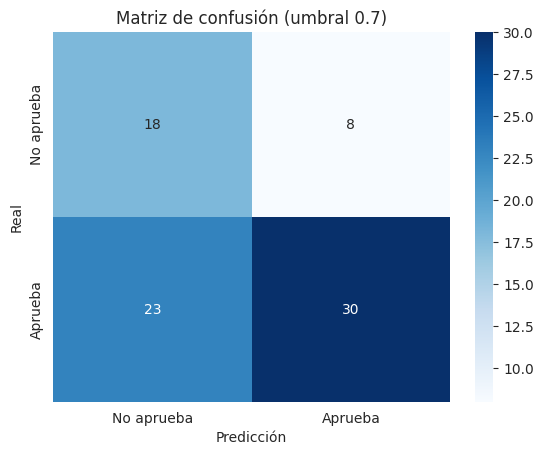

In [120]:
# Matriz de confusión con el umbral recomendado (0.7)
pred_07 = (probabilidades >= 0.7).astype(int)
cm = confusion_matrix(y_test_log, pred_07)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No aprueba", "Aprueba"], yticklabels=["No aprueba", "Aprueba"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión (umbral 0.7)")
plt.show()

**Pregunta crítica: ¿qué umbral elegiríamos?**

Elegimos el umbral **0.7**. El objetivo de la institución es no dejar sin apoyo a ningún estudiante en riesgo, y esos estudiantes son los que **no aprueban**. Por eso nos importa el recall de esa clase, es decir, qué proporción de los estudiantes en riesgo logramos detectar. Como el modelo estima la probabilidad de aprobar, con 0.7 marcamos como "en riesgo" a todo estudiante con probabilidad menor de 0.7, lo que alerta a más estudiantes que con 0.5 o 0.3.

El recall de la clase "no aprueba" sube con el umbral: 0.115 con 0.3, 0.346 con 0.5 y 0.692 con 0.7. Según la matriz de confusión, con 0.7 detectamos a 18 de los 26 estudiantes en riesgo del conjunto de prueba.

**Costo de esta decisión:**
- **Más falsas alarmas.** Se alertaría a 41 de los 79 estudiantes, y 23 de ellos habrían aprobado igualmente. La precisión de la clase "no aprueba" baja a 0.439, y eso exige más recursos de tutoría.
- **Menor exactitud global.** Baja de 0.696 a 0.608.
- **El modelo no detecta a todos.** 8 estudiantes en riesgo (cerca del 31 %) siguen sin ser alertados. Para acercarnos a "ninguno" habría que subir más el umbral y aceptar todavía más falsas alarmas, o complementar el modelo con el criterio de docentes y tutores.

Consideramos aceptable este costo: ofrecer apoyo a un estudiante que no lo necesitaba cuesta poco, y dejar sin apoyo a uno que sí lo necesitaba puede significar que repruebe. Por eso recomendamos usar el modelo como herramienta de alerta temprana y no como mecanismo definitivo para tomar decisiones sobre los estudiantes.

### Apoyo para las conclusiones: coeficientes de la regresión logística

In [121]:
# Apoyo para la pregunta 1: coeficientes de mayor magnitud de la regresión logística
nombres_log = modelo_log.named_steps["prep"].get_feature_names_out()
coef_log = pd.Series(modelo_log.named_steps["modelo"].coef_[0], index=nombres_log)
coef_log.reindex(coef_log.abs().sort_values(ascending=False).index).head(8).round(3)

,0
cat__schoolsup_yes,-0.914
cat__Mjob_teacher,-0.697
cat__sex_M,0.621
cat__reason_other,0.589
cat__Fjob_teacher,0.550
num__failures,-0.550
cat__famsup_yes,-0.535
cat__Fjob_other,0.526


# Conclusiones y reflexión ética

**1. Variables que más influyen.** Con las notas anteriores, G2 y G1 dominan (correlación de 0.90 y 0.80 con G3). Sin ellas, lo más asociado a la nota es haber reprobado antes (failures) y querer estudios superiores (higher); en la logística pesan también schoolsup, Mjob_teacher y el sexo. Son asociaciones, no causas.

**2. Limitaciones.** Solo 395 estudiantes de matemáticas de dos escuelas y 79 en prueba, así que las métricas varían mucho. El Modelo B explica solo el 3.6 % de G3, los 38 estudiantes con nota 0 son muy difíciles de predecir y los residuos no son normales.

**3. Ética.** No sería justo negar una beca con este modelo: sexo, situación familiar o alcohol no son mérito del estudiante, y con umbral 0.7 más de la mitad de los alertados sí aprobaría. Sí sirve como alerta temprana para ofrecer tutorías, con revisión humana y sin castigos.

**4. Recomendaciones.** Usar la logística (umbral 0.7) solo para priorizar apoyo, investigar los casos de nota 0, recolectar datos durante el semestre y validar con más datos y validación cruzada.

## Referencias
Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008)* (pp. 5-12). EUROSIS.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
